# LAB 09 — Fine-tuning BERT cho NER (CoNLL-2003)

1. Dữ liệu, tokenize với `word_ids`, alignment (Strategy A chính, Strategy B để so sánh);
2. Một batch đi qua model: `tokens`, `input_ids`, `attention_mask`, `word_ids`, `labels`, `logits`, `predictions`;
3. Fine-tune `bert-base-cased` (A và B), baseline Logistic Regression (`baseline_ner.py`);
4. **Exp 2** baseline vs Transformer; **Exp 3** token-level vs entity-level; **Exp 4** theo loại entity; **Exp 5** theo độ dài entity;
5. Entity hiếm (seen / unseen), ảnh hưởng của subword, confusion matrix, error analysis, context analysis.

In [1]:
import os, warnings
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"; os.environ["TRANSFORMERS_VERBOSITY"] = "error"
warnings.filterwarnings("ignore")
import time, math, random, json
from collections import Counter, defaultdict
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch, torch.nn.functional as F
import transformers; transformers.logging.set_verbosity_error()
from transformers import AutoTokenizer, AutoModelForTokenClassification, get_linear_schedule_with_warmup
from seqeval.metrics import f1_score as seqeval_f1, classification_report
import baseline_ner as bn
from baseline_ner import LABELS, TYPES, IGNORE
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 140)
SEED, MODEL, MAX_LEN = 42, "bert-base-cased", 128
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| transformers", transformers.__version__, "|", DEVICE,
      torch.cuda.get_device_name() if torch.cuda.is_available() else "")
if os.environ.get("LAB9_LOG"):                       # ghi thêm mọi dòng print ra file để theo dõi tiến độ
    import builtins
    _print = builtins.print
    def _tee(*a, **k):
        _print(*a, **k)
        with open(os.environ["LAB9_LOG"], "a", encoding="utf-8") as f:
            f.write(time.strftime("%H:%M:%S ") + " ".join(map(str, a)) + "\n")
    builtins.print = _tee
RESULTS = []
def log(exp, setting, metric, value):
    RESULTS.append({"experiment": exp, "setting": setting, "metric": metric, "value": float(value)})
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

torch 2.6.0+cu124 | transformers 5.17.0 | cuda NVIDIA GeForce RTX 3050 Laptop GPU


## 1. Dữ liệu và alignment

In [2]:
data = bn.load_conll()
for k, v in data.items():
    n_ent = sum(len(bn.bio_to_spans(t)) for t in v["tags"])
    print(f"{k:10}: {len(v['tokens'])} câu, {sum(map(len, v['tokens']))} word, {n_ent} entity")
train_types = Counter(s[2] for t in data["train"]["tags"] for s in bn.bio_to_spans(t))
print("Số entity train theo loại:", dict(train_types))

tok = AutoTokenizer.from_pretrained(MODEL)
def encode(split):
    enc = tok(data[split]["tokens"], is_split_into_words=True, truncation=True, max_length=MAX_LEN)
    wids = [enc.word_ids(i) for i in range(len(enc["input_ids"]))]
    lab = {s: [bn.align_labels(w, t, s) for w, t in zip(wids, data[split]["tags"])] for s in ["A", "B"]}
    return {"ids": enc["input_ids"], "wids": wids, "labels": lab}
ENC = {k: encode(k) for k in data}
n_trunc = sum(max(w for w in ws if w is not None) + 1 < len(t) for ws, t in zip(ENC["test"]["wids"], data["test"]["tokens"]))
for s in ["A", "B"]:
    lab = [l for x in ENC["train"]["labels"][s] for l in x]
    print(f"Strategy {s}: {len(lab)} token train, {sum(l != IGNORE for l in lab)} token có nhãn tính loss "
          f"({np.mean([l != IGNORE for l in lab]):.1%})")
print("Câu test bị cắt bởi max_length = 128:", n_trunc)

train     : 14041 câu, 203621 word, 23499 entity
validation: 3250 câu, 51362 word, 5942 entity
test      : 3453 câu, 46435 word, 5648 entity
Số entity train theo loại: {'ORG': 6321, 'MISC': 3438, 'PER': 6600, 'LOC': 7140}


Strategy A: 300632 token train, 203593 token có nhãn tính loss (67.7%)
Strategy B: 300632 token train, 272550 token có nhãn tính loss (90.7%)
Câu test bị cắt bởi max_length = 128: 2


## 2. Một batch đi qua model

In [3]:
def make_batches(split, strategy, bs, shuffle=False, seed=SEED):
    ids, labs = ENC[split]["ids"], ENC[split]["labels"][strategy]
    idx = np.arange(len(ids))
    if shuffle:
        np.random.default_rng(seed).shuffle(idx)
    for s in range(0, len(idx), bs):
        b = idx[s:s + bs]
        L = max(len(ids[i]) for i in b)
        x = torch.full((len(b), L), tok.pad_token_id); m = torch.zeros(len(b), L, dtype=torch.long)
        y = torch.full((len(b), L), IGNORE)
        for j, i in enumerate(b):
            n = len(ids[i]); x[j, :n] = torch.tensor(ids[i]); m[j, :n] = 1; y[j, :n] = torch.tensor(labs[i])
        yield b, x, m, y

set_seed()
model = AutoModelForTokenClassification.from_pretrained(MODEL, num_labels=len(LABELS),
                                                        id2label=dict(enumerate(LABELS)), label2id={l: i for i, l in enumerate(LABELS)})
print("head:", model.classifier, f"→ {sum(p.numel() for p in model.classifier.parameters())} tham số; "
      f"tổng {sum(p.numel() for p in model.parameters()):,}")
b, x, m, y = next(make_batches("train", "A", 8))
with torch.no_grad():
    out = model(input_ids=x, attention_mask=m, output_hidden_states=True)
print("tokens[0]:        ", tok.convert_ids_to_tokens(x[0])[:14])
print("word_ids[0]:      ", ENC["train"]["wids"][b[0]][:14])
for name, t in [("input_ids", x), ("attention_mask", m), ("labels", y), ("hidden states H", out.hidden_states[-1]),
                ("logits Z", out.logits), ("predictions", out.logits.argmax(-1))]:
    print(f"{name:16} {tuple(t.shape)}")
print("labels[0]:        ", y[0][:14].tolist())
print("predictions[0] (chưa train):", out.logits.argmax(-1)[0][:14].tolist())
del model

head: Linear(in_features=768, out_features=9, bias=True) → 6921 tham số; tổng 107,726,601


tokens[0]:         ['[CLS]', 'EU', 'rejects', 'German', 'call', 'to', 'boycott', 'British', 'la', '##mb', '.', '[SEP]', '[PAD]', '[PAD]']
word_ids[0]:       [None, 0, 1, 2, 3, 4, 5, 6, 7, 7, 8, None]
input_ids        (8, 50)
attention_mask   (8, 50)
labels           (8, 50)
hidden states H  (8, 50, 768)
logits Z         (8, 50, 9)
predictions      (8, 50)
labels[0]:         [-100, 3, 0, 7, 0, 0, 0, 7, 0, -100, 0, -100, -100, -100]
predictions[0] (chưa train): [6, 4, 4, 4, 2, 2, 4, 2, 4, 4, 4, 0, 4, 4]


Batch có B = 8 câu, T = token dài nhất của batch (dynamic padding). H: B × T × 768, Z = HW + b: B × T × 9, labels: B × T. Đúng với Calculation Exercise 3 khi T = 128.

## 3. Fine-tuning

AdamW lr 3e-5, weight decay 0.01, warmup 10% rồi giảm tuyến tính, batch 16, 3 epoch, bf16 autocast, clip 1.0. Chọn epoch có **entity F1 trên validation** cao nhất. Đánh giá ở mức word: lấy dự đoán ở subword đầu của mỗi word cho cả A và B, để so được với gold và với baseline.

In [4]:
@torch.no_grad()
def predict(model, split, strategy="A", bs=64):
    """Trả về (nhãn word-level của mọi câu, xác suất max ở subword đầu của từng word)."""
    model.eval()
    tags, conf = [None] * len(ENC[split]["ids"]), [None] * len(ENC[split]["ids"])
    for b, x, m, _ in make_batches(split, strategy, bs):
        for _ in range(5):                                   # GPU đôi khi ra NaN (xem LAB 07–08) → tính lại
            with torch.autocast(DEVICE.type, dtype=torch.bfloat16):
                logits = model(input_ids=x.to(DEVICE), attention_mask=m.to(DEVICE)).logits.float()
            if torch.isfinite(logits).all():
                break
        prob = logits.softmax(-1).cpu()
        for j, i in enumerate(b):
            wids, n_w = ENC[split]["wids"][i], len(data[split]["tokens"][i])
            p = prob[j, :len(wids)]
            tags[i] = bn.word_predictions(wids, p.argmax(-1).tolist(), n_w)
            c, prev = [1.0] * n_w, None
            for k, w in enumerate(wids):
                if w is not None and w != prev:
                    c[w] = float(p[k].max())
                prev = w
            conf[i] = c
    return tags, conf

def train(strategy, epochs=3, bs=16, lr=3e-5, seed=SEED):
    """Có checkpoint theo epoch trong ckpt/: GPU của máy này thỉnh thoảng gặp 'CUDA illegal memory access'
    (làm hỏng cả process), nên chạy lại notebook sẽ tiếp tục từ epoch đã xong thay vì train lại từ đầu."""
    os.makedirs("ckpt", exist_ok=True)
    final, state = f"ckpt/{strategy}_final.pt", f"ckpt/{strategy}_epoch.pt"
    model = AutoModelForTokenClassification.from_pretrained(MODEL, num_labels=len(LABELS))
    if os.path.exists(final):                               # đã train xong ở lần chạy trước
        ck = torch.load(final, weights_only=False)
        model.load_state_dict(ck["model"])
        print(f"  [{strategy}] nạp lại model đã train từ {final}")
        return model.to(DEVICE), ck["info"]
    set_seed(seed)
    model.to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    steps = epochs * math.ceil(len(ENC["train"]["ids"]) / bs)
    sched = get_linear_schedule_with_warmup(opt, int(0.1 * steps), steps)
    best, hist, skipped, t_train, start = (-1, None, 0), [], 0, 0.0, 1
    if os.path.exists(state):                               # tiếp tục sau lỗi GPU
        ck = torch.load(state, weights_only=False)
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); sched.load_state_dict(ck["sched"])
        best, hist, skipped, t_train, start = ck["best"], ck["hist"], ck["skipped"], ck["t_train"], ck["epoch"] + 1
        print(f"  [{strategy}] tiếp tục từ epoch {start}")
    for ep in range(start, epochs + 1):
        model.train(); t0 = time.time(); tot = n = 0
        for _, x, m, y in make_batches("train", strategy, bs, shuffle=True, seed=seed + ep):
            x, m, y = x.to(DEVICE), m.to(DEVICE), y.to(DEVICE)
            with torch.autocast(DEVICE.type, dtype=torch.bfloat16):
                logits = model(input_ids=x, attention_mask=m).logits.float()
            loss = F.cross_entropy(logits.view(-1, len(LABELS)), y.view(-1), ignore_index=IGNORE)
            opt.zero_grad(set_to_none=True); loss.backward()
            gn = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            if not (torch.isfinite(loss) and torch.isfinite(gn)):
                skipped += 1; sched.step(); continue
            opt.step(); sched.step(); tot += loss.item(); n += 1
        torch.cuda.synchronize(); t_train += time.time() - t0
        vp, _ = predict(model, "validation", strategy)
        s = bn.entity_scores(data["validation"]["tags"], vp)
        hist.append({"epoch": ep, "train_loss": tot / n, "val_P": s["precision"], "val_R": s["recall"], "val_F1": s["f1"]})
        print(f"  [{strategy}] epoch {ep}: train loss {tot / n:.4f} | val entity F1 {s['f1']:.4f} | {time.time() - t0:.0f}s")
        if s["f1"] > best[0]:
            best = (s["f1"], {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}, ep)
        torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "sched": sched.state_dict(), "best": best,
                    "hist": hist, "skipped": skipped, "t_train": t_train, "epoch": ep}, state)
    model.load_state_dict(best[1])
    info = {"hist": hist, "best_epoch": best[2], "train_time": t_train, "skipped": skipped}
    torch.save({"model": best[1], "info": info}, final); os.remove(state)
    return model, info

models, info = {}, {}
for s in ["A", "B"]:
    models[s], info[s] = train(s)
    print(f"Strategy {s}: best epoch {info[s]['best_epoch']}, train {info[s]['train_time']:.0f}s, skipped {info[s]['skipped']}")
    log("train", f"strategy {s}", "train_time", info[s]["train_time"]); log("train", f"strategy {s}", "skipped_steps", info[s]["skipped"])
    log("train", f"strategy {s}", "best_epoch", info[s]["best_epoch"])
    for h in info[s]["hist"]:
        log("train", f"strategy {s} epoch {h['epoch']}", "val_entity_f1", h["val_F1"])
    models[s].cpu(); torch.cuda.empty_cache()     # GPU 4 GB: giữ 2 model cùng lúc làm VRAM tràn sang RAM, chậm ~6 lần
pd.DataFrame([{"strategy": s, **h} for s in info for h in info[s]["hist"]]).round(4)

  [A] nạp lại model đã train từ ckpt/A_final.pt


Strategy A: best epoch 3, train 331s, skipped 67


  [B] nạp lại model đã train từ ckpt/B_final.pt
Strategy B: best epoch 3, train 940s, skipped 43


,strategy,epoch,train_loss,val_P,val_R,val_F1
0,A,1,0.2209,0.9281,0.9344,0.9312
1,A,2,0.0270,0.9381,0.9458,0.9419
2,A,3,0.0122,0.9445,0.9517,0.9481
3,B,1,0.2712,0.9367,0.9394,0.9381
4,B,2,0.0444,0.9400,0.9467,0.9433
5,B,3,0.0217,0.9447,0.9520,0.9484


## 4. Baseline (word features → Logistic Regression)

In [5]:
t0 = time.time()
vec, clf = bn.train_baseline(data)
t_base = time.time() - t0
print(f"baseline: {len(vec.vocabulary_)} feature, train {t_base:.0f}s")
log("train", "baseline", "train_time", t_base)

baseline: 133786 feature, train 35s


## 5. Exp 2 + Exp 3 — Baseline vs Transformer; token-level vs entity-level (test)

In [6]:
gold = {sp: data[sp]["tags"] for sp in ["validation", "test"]}
PRED, CONF = {}, {}
for sp in ["validation", "test"]:
    PRED[("baseline", sp)] = bn.predict_baseline(vec, clf, data[sp]["tokens"])
    for s in ["A", "B"]:
        models[s].to(DEVICE)
        PRED[(f"BERT ({s})", sp)], CONF[(f"BERT ({s})", sp)] = predict(models[s], sp, s)
        models[s].cpu(); torch.cuda.empty_cache()
rows = []
for name in ["baseline", "BERT (A)", "BERT (B)"]:
    for sp in ["validation", "test"]:
        e = bn.entity_scores(gold[sp], PRED[(name, sp)])
        tp_, tr_, tf_ = bn.token_f1(gold[sp], PRED[(name, sp)])
        r = {"model": name, "split": sp, "entity P": e["precision"], "entity R": e["recall"], "entity F1": e["f1"],
             "seqeval F1": seqeval_f1(gold[sp], PRED[(name, sp)]), "token acc": bn.token_accuracy(gold[sp], PRED[(name, sp)]),
             "token P (≠O)": tp_, "token R (≠O)": tr_, "token F1 (≠O)": tf_, "TP": e["tp"], "FP": e["fp"], "FN": e["fn"]}
        rows.append(r)
        for k, v in r.items():
            if k not in ("model", "split"):
                log("Exp2", f"{name} | {sp}", k, v)
exp2 = pd.DataFrame(rows).set_index(["model", "split"])
exp2.round(4)

entity P  entity R  entity F1  seqeval F1  token acc  token P (≠O)  token R (≠O)  token F1 (≠O)    TP    FP    FN
model    split                                                                                                                        
baseline validation    0.8343    0.8524     0.8433      0.8433     0.9749        0.8974        0.8620         0.8794  5065  1006   877
         test          0.7424    0.7783     0.7600      0.7600     0.9577        0.8206        0.8076         0.8140  4396  1525  1252
BERT (A) validation    0.9445    0.9517     0.9481      0.9481     0.9910        0.9580        0.9571         0.9576  5655   332   287
         test          0.9052    0.9164     0.9108      0.9108     0.9826        0.9170        0.9299         0.9234  5176   542   472
BERT (B) validation    0.9447    0.9520     0.9484      0.9484     0.9911        0.9582        0.9585         0.9583  5657   331   285
         test          0.9071    0.9217     0.9144      0.9144     0.9827        0.9177        0.9328         0.9252  5206   533   442

Ví dụ của đề (mục 19): gold `New York → B-LOC I-LOC`, dự đoán `B-LOC O`.

In [7]:
g, p = [["B-LOC", "I-LOC"]], [["B-LOC", "O"]]
print(f"token accuracy = {bn.token_accuracy(g, p):.2f} | entity: {bn.entity_scores(g, p)} | gold span {bn.bio_to_spans(g[0])}, pred span {bn.bio_to_spans(p[0])}")
# đếm trên test: entity mà ít nhất một token đúng nhãn nhưng entity không khớp
for name in ["baseline", "BERT (A)"]:
    part = tot = 0
    for gs, ps in zip(gold["test"], PRED[(name, "test")]):
        pspans = set(bn.bio_to_spans(ps))
        for (a, e, t) in bn.bio_to_spans(gs):
            if (a, e, t) not in pspans:
                tot += 1
                part += any(gs[i] == ps[i] for i in range(a, e))
    print(f"{name}: {tot} gold entity bị sai; {part} ({part / tot:.0%}) trong số đó vẫn có ≥ 1 token đúng nhãn (được token-level tính điểm)")
    log("Exp3", name, "missed entities with ≥1 correct token", part / tot)

token accuracy = 0.50 | entity: {'precision': 0.0, 'recall': 0.0, 'f1': 0.0, 'tp': 0, 'fp': 1, 'fn': 1} | gold span [(0, 2, 'LOC')], pred span [(0, 1, 'LOC')]
baseline: 1252 gold entity bị sai; 317 (25%) trong số đó vẫn có ≥ 1 token đúng nhãn (được token-level tính điểm)
BERT (A): 472 gold entity bị sai; 85 (18%) trong số đó vẫn có ≥ 1 token đúng nhãn (được token-level tính điểm)


## 6. Exp 4 — Theo loại entity

In [8]:
rows = []
for name in ["baseline", "BERT (A)", "BERT (B)"]:
    rep = bn.entity_report(gold["test"], PRED[(name, "test")])
    for t in TYPES:
        rows.append({"model": name, "type": t, **{k: rep[t][k] for k in ["precision", "recall", "f1", "support", "tp", "fp", "fn"]},
                     "train entities": train_types[t]})
ent = pd.DataFrame(rows)
ent.to_csv("entity_metrics.csv", index=False)
print("seqeval classification_report (BERT A, test) để đối chiếu:")
print(classification_report(gold["test"], PRED[("BERT (A)", "test")], digits=4))
ent.pivot(index="type", columns="model", values="f1").round(4).assign(**{"train entities": [train_types[t] for t in sorted(TYPES)]})

seqeval classification_report (BERT A, test) để đối chiếu:


              precision    recall  f1-score   support

         LOC     0.9297    0.9281    0.9289      1668
        MISC     0.7893    0.8162    0.8025       702
         ORG     0.8752    0.9121    0.8933      1661
         PER     0.9649    0.9524    0.9586      1617

   micro avg     0.9052    0.9164    0.9108      5648
   macro avg     0.8898    0.9022    0.8958      5648
weighted avg     0.9063    0.9164    0.9112      5648



model,BERT (A),BERT (B),baseline,train entities
type,,,,
LOC,0.9289,0.9345,0.8339,7140
MISC,0.8025,0.8035,0.7389,3438
ORG,0.8933,0.8993,0.6442,6321
PER,0.9586,0.9602,0.8092,6600


In [9]:
ent[ent.model == "BERT (A)"].set_index("type").round(4)

,model,precision,recall,f1,support,tp,fp,fn,train entities
type,,,,,,,,,
PER,BERT (A),0.9649,0.9524,0.9586,1617,1540,56,77,6600
ORG,BERT (A),0.8752,0.9121,0.8933,1661,1515,216,146,6321
LOC,BERT (A),0.9297,0.9281,0.9289,1668,1548,117,120,7140
MISC,BERT (A),0.7893,0.8162,0.8025,702,573,153,129,3438


## 7. Exp 5 — Theo độ dài entity (số word)

FN và TP được xếp nhóm theo độ dài của entity gold; FP theo độ dài của entity dự đoán.

In [10]:
def len_bucket(span, sid=None):
    n = span[1] - span[0]
    return "4+" if n >= 4 else str(n)
rows = []
for name in ["baseline", "BERT (A)", "BERT (B)"]:
    rep = bn.entity_report(gold["test"], PRED[(name, "test")], key=len_bucket)
    for k in ["1", "2", "3", "4+"]:
        rows.append({"model": name, "length": k, **{c: rep[k][c] for c in ["precision", "recall", "f1", "support"]}})
        log("Exp5", f"{name} | len {k}", "f1", rep[k]["f1"]); log("Exp5", f"{name} | len {k}", "support", rep[k]["support"])
L = pd.DataFrame(rows)
print(L.pivot(index="length", columns="model", values="f1").round(4))
print("\nsupport (số entity gold):", L[L.model == "BERT (A)"].set_index("length").support.to_dict())
gl = Counter((len_bucket(s), s[2]) for t in gold["test"] for s in bn.bio_to_spans(t))
print("Phân bố loại theo độ dài (test):"); print(pd.Series(gl).unstack(fill_value=0))

model   BERT (A)  BERT (B)  baseline
length                              
1         0.9080    0.9092    0.7368
2         0.9242    0.9302    0.8351
3         0.8692    0.8861    0.6300
4+        0.8507    0.8702    0.4731

support (số entity gold): {'1': 3574, '2': 1776, '3': 236, '4+': 62}
Phân bố loại theo độ dài (test):
     LOC  MISC   ORG   PER
1   1436   525  1082   531
2    207   148   403  1018
3     25    23   122    66
4+     0     6    54     2


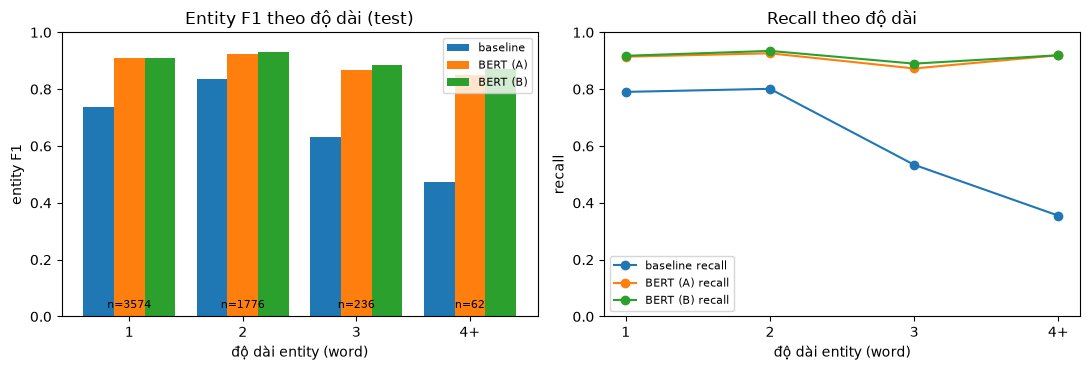

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
xs = np.arange(4)
for k, name in enumerate(["baseline", "BERT (A)", "BERT (B)"]):
    d = L[L.model == name]
    ax[0].bar(xs + (k - 1) * 0.27, d.f1, 0.27, label=name)
    ax[1].plot(xs, d.recall, "-o", label=f"{name} recall")
ax[0].set(xticks=xs, xticklabels=["1", "2", "3", "4+"], xlabel="độ dài entity (word)", ylabel="entity F1", ylim=(0, 1), title="Entity F1 theo độ dài (test)")
for x_, n in zip(xs, L[L.model == "BERT (A)"].support):
    ax[0].text(x_, 0.03, f"n={n}", ha="center", fontsize=8)
ax[0].legend(fontsize=8)
ax[1].set(xticks=xs, xticklabels=["1", "2", "3", "4+"], xlabel="độ dài entity (word)", ylabel="recall", ylim=(0, 1), title="Recall theo độ dài")
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig("entity_length_analysis.png", dpi=120); plt.show()

## 8. Entity hiếm và subword (Prediction 3)

- **seen:** chuỗi entity (cùng loại) có xuất hiện trong train;
- **unseen:** chưa từng xuất hiện.

Thêm phân nhóm theo việc entity có word nào bị tách thành subword hay không.

In [12]:
train_ents = Counter((" ".join(w[a:e]), t) for w, tg in zip(data["train"]["tokens"], data["train"]["tags"]) for a, e, t in bn.bio_to_spans(tg))
test_words = data["test"]["tokens"]
def seen_key(span, sid):
    return "seen" if (" ".join(test_words[sid][span[0]:span[1]]), span[2]) in train_ents else "unseen"
def split_key(span, sid):
    return "có word bị tách" if any(len(tok.tokenize(w)) > 1 for w in test_words[sid][span[0]:span[1]]) else "không bị tách"
rows = []
for name in ["baseline", "BERT (A)", "BERT (B)"]:
    for kname, key in [("seen / unseen", seen_key), ("subword", split_key)]:
        rep = bn.entity_report(gold["test"], PRED[(name, "test")], key=key)
        for g_, r in rep.items():
            rows.append({"model": name, "nhóm": kname, "giá trị": g_, **{c: r[c] for c in ["precision", "recall", "f1", "support"]}})
            log("Rare", f"{name} | {g_}", "f1", r["f1"]); log("Rare", f"{name} | {g_}", "recall", r["recall"])
R = pd.DataFrame(rows)
piv = R.pivot_table(index=["nhóm", "giá trị"], columns="model", values=["recall", "f1"]).round(4)
piv.columns = [f"{m} {c}" for c, m in piv.columns]
piv.join(R[R.model == "BERT (A)"].set_index(["nhóm", "giá trị"]).support)

BERT (A) f1  BERT (B) f1  baseline f1  BERT (A) recall  BERT (B) recall  baseline recall  support
nhóm          giá trị                                                                                                           
seen / unseen seen                  0.9621       0.9636       0.9137           0.9588           0.9598           0.9150     2963
              unseen                0.8553       0.8614       0.5980           0.8696           0.8797           0.6276     2685
subword       có word bị tách       0.9030       0.9044       0.7424           0.9112           0.9152           0.7356     3029
              không bị tách         0.9199       0.9260       0.7789           0.9225           0.9294           0.8278     2619

In [13]:
# tần suất trong train của entity gold (theo chuỗi) → recall
def freq_bucket(span, sid):
    c = train_ents[(" ".join(test_words[sid][span[0]:span[1]]), span[2])]
    return "0" if c == 0 else "1–2" if c <= 2 else "3–10" if c <= 10 else ">10"
rows = []
for name in ["baseline", "BERT (A)"]:
    rep = bn.entity_report(gold["test"], PRED[(name, "test")], key=freq_bucket)
    for k in ["0", "1–2", "3–10", ">10"]:
        rows.append({"model": name, "số lần xuất hiện trong train": k, "recall": rep[k]["recall"], "support": rep[k]["support"]})
pd.DataFrame(rows).pivot(index="số lần xuất hiện trong train", columns="model", values="recall").round(4).join(
    pd.DataFrame(rows)[lambda d: d.model == "BERT (A)"].set_index("số lần xuất hiện trong train").support).loc[["0", "1–2", "3–10", ">10"]]

,BERT (A),baseline,support
số lần xuất hiện trong train,,,
0,0.8696,0.6276,2685
1–2,0.9110,0.7757,584
3–10,0.9534,0.8968,901
>10,0.9811,0.9811,1478


## 9. Confusion matrix

baseline
               PER   ORG   LOC  MISC  sai biên  bỏ sót
PER           1385    34    41     8        78      71
ORG             86  1081    96    26       226     146
LOC             26    82  1408    10        71      71
MISC            22    33    15   522        57      53
O (spurious)    86   127    32    61         0       0 

BERT (A)
               PER   ORG   LOC  MISC  sai biên  bỏ sót
PER           1540    31    15     1        16      14
ORG             11  1515    35    17        63      20
LOC              3    47  1548    15        43      12
MISC             5    31    13   573        57      23
O (spurious)    19    49    12    47         0       0 



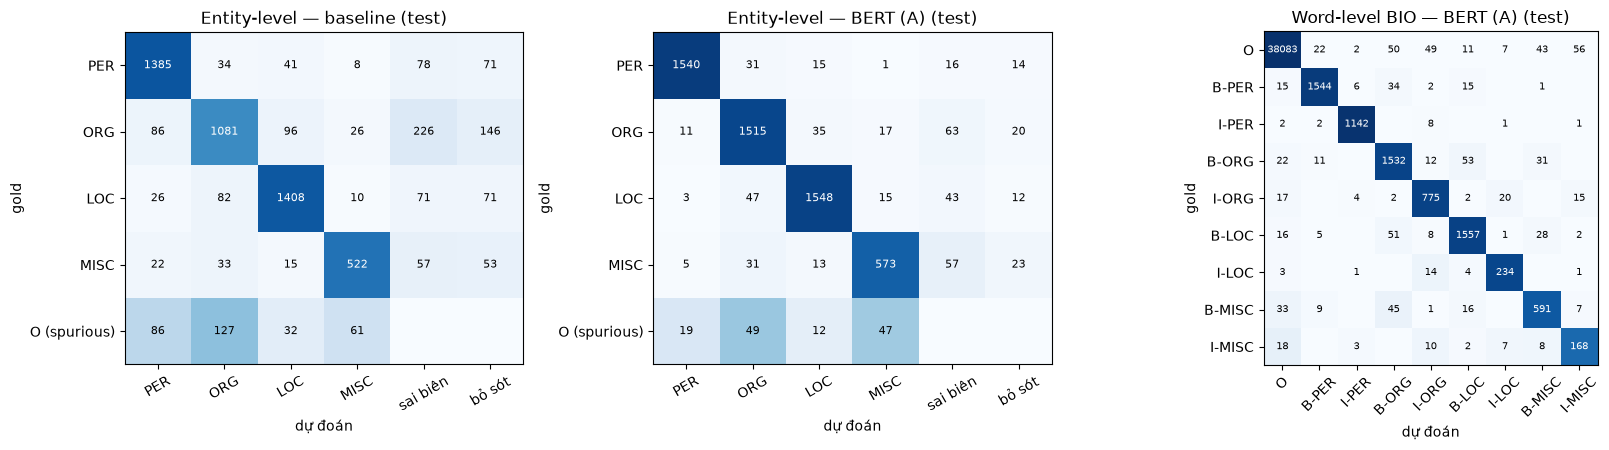

In [14]:
def span_confusion(gold_seqs, pred_seqs):
    """Mỗi entity gold → loại dự đoán nếu có span dự đoán trùng biên; 'sai biên' nếu chỉ chồng lấn; 'bỏ sót' nếu không chồng.
    Mỗi span dự đoán không chồng lên gold nào → hàng 'O (spurious)'."""
    cm = Counter()
    for g, p in zip(gold_seqs, pred_seqs):
        gs, ps = bn.bio_to_spans(g), bn.bio_to_spans(p)
        pmap = {(a, e): t for a, e, t in ps}
        for a, e, t in gs:
            if (a, e) in pmap: cm[(t, pmap[(a, e)])] += 1
            elif any(pa < e and a < pe for pa, pe, _ in ps): cm[(t, "sai biên")] += 1
            else: cm[(t, "bỏ sót")] += 1
        for a, e, t in ps:
            if not any(ga < e and a < ge for ga, ge, _ in gs): cm[("O (spurious)", t)] += 1
    rows, cols = TYPES + ["O (spurious)"], TYPES + ["sai biên", "bỏ sót"]
    return pd.DataFrame([[cm[(r, c)] for c in cols] for r in rows], index=rows, columns=cols)

cms = {name: span_confusion(gold["test"], PRED[(name, "test")]) for name in ["baseline", "BERT (A)"]}
for name, c in cms.items():
    print(name); print(c, "\n")
flat = lambda seqs: [t for s in seqs for t in s]
from sklearn.metrics import confusion_matrix as sk_cm
tok_cm = sk_cm(flat(gold["test"]), flat(PRED[("BERT (A)", "test")]), labels=LABELS)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6), gridspec_kw={"width_ratios": [1, 1, 1.25]})
for a, (name, c) in zip(ax[:2], cms.items()):
    v = c.values.astype(float)
    a.imshow(v / v.sum(1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
    for i in range(v.shape[0]):
        for j in range(v.shape[1]):
            if c.index[i] == "O (spurious)" and c.columns[j] in ("sai biên", "bỏ sót"): continue
            a.text(j, i, int(v[i, j]), ha="center", va="center", fontsize=8, color="white" if v[i, j] / v[i].sum() > 0.5 else "black")
    a.set(xticks=range(v.shape[1]), xticklabels=c.columns, yticks=range(v.shape[0]), yticklabels=c.index,
          xlabel="dự đoán", ylabel="gold", title=f"Entity-level — {name} (test)")
    a.tick_params(axis="x", rotation=30)
n = tok_cm / tok_cm.sum(1, keepdims=True)
ax[2].imshow(n, cmap="Blues", vmin=0, vmax=1)
for i in range(9):
    for j in range(9):
        if tok_cm[i, j]: ax[2].text(j, i, tok_cm[i, j], ha="center", va="center", fontsize=7, color="white" if n[i, j] > 0.5 else "black")
ax[2].set(xticks=range(9), xticklabels=LABELS, yticks=range(9), yticklabels=LABELS, xlabel="dự đoán", ylabel="gold", title="Word-level BIO — BERT (A) (test)")
ax[2].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.savefig("confusion_matrix.png", dpi=120); plt.show()

## 10. Error analysis (BERT A, test)

Mỗi lỗi entity-level được xếp vào một nhóm:

- **spurious** (FP): span dự đoán không chồng lên entity gold nào;
- **missing** (FN): entity gold không có span dự đoán nào chồng lên;
- **wrong type:** đúng biên, sai loại;
- **wrong boundary:** chồng lấn, cùng loại, sai biên;
- **type + boundary:** chồng lấn, sai cả hai.

In [15]:
def classify_errors(gold_seqs, pred_seqs, conf=None):
    out = []
    for sid, (g, p) in enumerate(zip(gold_seqs, pred_seqs)):
        gs, ps = bn.bio_to_spans(g), bn.bio_to_spans(p)
        gset, pset = set(gs), set(ps)
        used = set()
        for (a, e, t) in gs:
            if (a, e, t) in pset: continue
            ov = [s for s in ps if s[0] < e and a < s[1] and s not in gset]
            if not ov:
                out.append({"sid": sid, "kind": "missing", "gold": (a, e, t), "pred": None})
            else:
                for s in ov:
                    used.add(s)
                    kind = "wrong type" if (s[0], s[1]) == (a, e) else ("wrong boundary" if s[2] == t else "type + boundary")
                    out.append({"sid": sid, "kind": kind, "gold": (a, e, t), "pred": s})
        for s in ps:
            if s not in gset and s not in used and not any(ga < s[1] and s[0] < ge for ga, ge, _ in gs):
                out.append({"sid": sid, "kind": "spurious", "gold": None, "pred": s})
    df = pd.DataFrame(out)
    W = data["test"]["tokens"]
    df["gold text"] = [" ".join(W[r.sid][r.gold[0]:r.gold[1]]) + f" [{r.gold[2]}]" if r.gold else "—" for r in df.itertuples()]
    df["pred text"] = [" ".join(W[r.sid][r.pred[0]:r.pred[1]]) + f" [{r.pred[2]}]" if r.pred else "—" for r in df.itertuples()]
    if conf is not None:
        df["conf"] = [round(min(conf[r.sid][(r.pred or r.gold)[0]:(r.pred or r.gold)[1]]), 3) for r in df.itertuples()]
    df["seen in train"] = [("yes" if (" ".join(W[r.sid][(r.gold or r.pred)[0]:(r.gold or r.pred)[1]]), (r.gold or r.pred)[2]) in train_ents else "no")
                           for r in df.itertuples()]
    df["sentence"] = [" ".join(W[r.sid]) for r in df.itertuples()]
    return df

E = classify_errors(gold["test"], PRED[("BERT (A)", "test")], CONF[("BERT (A)", "test")])
Eb = classify_errors(gold["test"], PRED[("baseline", "test")])
summary = pd.DataFrame({"BERT (A)": E.kind.value_counts(), "baseline": Eb.kind.value_counts()}).fillna(0).astype(int)
for k, r in summary.iterrows():
    log("Errors", k, "BERT (A)", r["BERT (A)"]); log("Errors", k, "baseline", r["baseline"])
summary

,BERT (A),baseline
kind,,
missing,69,341
spurious,127,306
type + boundary,103,342
wrong boundary,114,409
wrong type,224,479


In [16]:
print("Loại nhầm thường gặp nhất (wrong type, gold → pred):")
print(E[E.kind == "wrong type"].apply(lambda r: f"{r.gold[2]} → {r.pred[2]}", axis=1).value_counts().head(6))
print("\nBiên sai: dự đoán dài hơn hay ngắn hơn gold?")
wb = E[E.kind == "wrong boundary"]
print(wb.apply(lambda r: "dài hơn" if (r.pred[1] - r.pred[0]) > (r.gold[1] - r.gold[0]) else ("ngắn hơn" if (r.pred[1] - r.pred[0]) < (r.gold[1] - r.gold[0]) else "lệch"), axis=1).value_counts())
print(f"\nTỉ lệ lỗi có entity chưa thấy trong train: {(E['seen in train'] == 'no').mean():.1%} "
      f"(trong toàn bộ entity gold test: {np.mean([seen_key(s, i) == 'unseen' for i, t in enumerate(gold['test']) for s in bn.bio_to_spans(t)]):.1%})")

Loại nhầm thường gặp nhất (wrong type, gold → pred):
LOC → ORG     47
ORG → LOC     35
MISC → ORG    31
PER → ORG     31
ORG → MISC    17
PER → LOC     15
Name: count, dtype: int64

Biên sai: dự đoán dài hơn hay ngắn hơn gold?
ngắn hơn    62
dài hơn     52
Name: count, dtype: int64

Tỉ lệ lỗi có entity chưa thấy trong train: 78.2% (trong toàn bộ entity gold test: 47.5%)


In [17]:
def show(kind, n, seed=0):
    d = E[E.kind == kind]
    d = d.sample(min(n, len(d)), random_state=seed)
    print(f"\n{'=' * 25} {kind.upper()} ({len(E[E.kind == kind])} lỗi)")
    for _, r in d.iterrows():
        print(f"[sid {r['sid']}] gold: {r['gold text']:35} pred: {r['pred text']:35} conf {r['conf']} | seen: {r['seen in train']}")
        print(f"     {r['sentence'][:230]}")
for k in ["spurious", "missing", "wrong boundary", "wrong type", "type + boundary"]:
    show(k, 7 if k != "type + boundary" else 3)


========================= SPURIOUS (127 lỗi)
[sid 422] gold: —                                   pred: NFC [ORG]                           conf 0.859 | seen: no
     The loss by Philadelphia allowed the idle Green Bay Packers ( 10-3 ) to clinch the first NFC playoff berth .
[sid 1469] gold: —                                   pred: Congress [ORG]                      conf 0.999 | seen: yes
     Aninat also said he was confident the Chilean Congress would ratify the treaty with Congress quickly .
[sid 3442] gold: —                                   pred: HONORARY [MISC]                     conf 0.517 | seen: no
     SOCCER - ENGLISHMAN CHARLTON IS MADE AN HONORARY IRISHMAN .
[sid 1027] gold: —                                   pred: Mediterranean [MISC]                conf 0.79 | seen: yes
     Mediterranean oil products were steady to mostly lower on Friday after Elf refinery workers voted to end their nine-day strike .
[sid 1295] gold: —                                   pred: Pope [

## 11. Context analysis — cùng surface form, khác loại entity

In [18]:
forms = defaultdict(Counter)
for sid, (w, t) in enumerate(zip(data["test"]["tokens"], gold["test"])):
    for a, e, ty in bn.bio_to_spans(t):
        forms[" ".join(w[a:e])][ty] += 1
amb = {f: c for f, c in forms.items() if len(c) > 1}
print(f"{len(amb)} surface form có ≥ 2 loại trong test. Nhiều nhất:")
amb_df = pd.DataFrame([{"form": f, **c, "total": sum(c.values())} for f, c in amb.items()]).fillna(0).sort_values("total", ascending=False)
print(amb_df.head(12).to_string(index=False))

def occurrences(form):
    out = []
    for sid, (w, t) in enumerate(zip(data["test"]["tokens"], gold["test"])):
        for a, e, ty in bn.bio_to_spans(t):
            if " ".join(w[a:e]) == form:
                pa = {(s[0], s[1]): s[2] for s in bn.bio_to_spans(PRED[("BERT (A)", "test")][sid])}
                pb = {(s[0], s[1]): s[2] for s in bn.bio_to_spans(PRED[("baseline", "test")][sid])}
                out.append({"form": form, "gold": ty, "BERT": pa.get((a, e), "✗"), "baseline": pb.get((a, e), "✗"),
                            "context": " ".join(w[max(0, a - 6):e + 6])})
    return out
ctx = []
for f in amb_df.form.head(25):
    occ = occurrences(f)
    for ty in sorted({o["gold"] for o in occ}):
        ctx.append(next(o for o in occ if o["gold"] == ty))
ctx = pd.DataFrame(ctx)
acc_amb = pd.DataFrame([o for f in amb for o in occurrences(f)])
print(f"\nTrên {len(acc_amb)} lần xuất hiện của các form mơ hồ: BERT đúng {np.mean(acc_amb.BERT == acc_amb.gold):.1%}, "
      f"baseline đúng {np.mean(acc_amb.baseline == acc_amb.gold):.1%}")
log("Context", "ambiguous forms", "BERT accuracy", np.mean(acc_amb.BERT == acc_amb.gold))
log("Context", "ambiguous forms", "baseline accuracy", np.mean(acc_amb.baseline == acc_amb.gold))
ctx.head(24)

64 surface form có ≥ 2 loại trong test. Nhiều nhất:
      form  LOC  ORG  total  MISC  PER
 Barcelona  2.0 22.0     24   0.0  0.0
  NEW YORK 19.0  3.0     22   0.0  0.0
  Santa Fe  2.0 16.0     18   0.0  0.0
   CHICAGO  6.0  7.0     13   0.0  0.0
WASHINGTON  4.0  8.0     12   0.0  0.0
  American  0.0  4.0     10   6.0  0.0
   DETROIT  2.0  7.0      9   0.0  0.0
    DALLAS  3.0  6.0      9   0.0  0.0
  New York  8.0  1.0      9   0.0  0.0
    Busang  5.0  4.0      9   0.0  0.0
    BOSTON  2.0  6.0      8   0.0  0.0
 Wimbledon  4.0  4.0      8   0.0  0.0



Trên 367 lần xuất hiện của các form mơ hồ: BERT đúng 86.1%, baseline đúng 65.4%


,form,gold,BERT,baseline,context
0,Barcelona,LOC,LOC,LOC,"' status committee , meeting in Barcelona , decided that although the Udinese"
1,Barcelona,ORG,ORG,ORG,Barcelona ( Spain ) 9 4 5
2,NEW YORK,LOC,LOC,LOC,NEW YORK 1996-12-06
3,NEW YORK,ORG,ORG,ORG,NEW YORK 10 6 .625 3
4,Santa Fe,LOC,LOC,PER,Wall St speculates about Santa Fe savior .
5,Santa Fe,ORG,ORG,PER,Santa Fe Pacific Gold Corp if Santa Fe rejects unsolicited suitor Newmont Mining Corp
6,CHICAGO,LOC,LOC,LOC,MONTREAL AT CHICAGO
7,CHICAGO,ORG,ORG,ORG,CHICAGO 12 12 3 71 67 27
8,WASHINGTON,LOC,LOC,LOC,PITTSBURGH AT WASHINGTON
9,WASHINGTON,ORG,ORG,ORG,WASHINGTON 13 12 1 69 66 27


## 12. Lưu kết quả và model

In [19]:
pd.DataFrame(RESULTS).to_csv("results.csv", index=False)
models["A"].save_pretrained("model_ner"); tok.save_pretrained("model_ner")
print(len(RESULTS), "dòng → results.csv | entity_metrics.csv | model_ner/ (Strategy A, dùng cho information_extraction.py)")

141 dòng → results.csv | entity_metrics.csv | model_ner/ (Strategy A, dùng cho information_extraction.py)
